In [2]:
%pip install seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("cleaned_titanic.csv")

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,Unknown,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,Unknown,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,Unknown,S


In [4]:
print("Dataset shape:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (891, 12)

Data types:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

Missing values:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64

Duplicate rows: 0


In [5]:
print("Descriptive Statistics:")
display(df.describe())

Descriptive Statistics:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.361582,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,13.019697,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [6]:
print("Sex distribution:")
print(df["Sex"].value_counts())

print("\nPassenger class distribution:")
print(df["Pclass"].value_counts())

print("\nEmbarkation distribution:")
print(df["Embarked"].value_counts())

print("\nSurvival distribution:")
print(df["Survived"].value_counts())

Sex distribution:
Sex
male      577
female    314
Name: count, dtype: int64

Passenger class distribution:
Pclass
3    491
1    216
2    184
Name: count, dtype: int64

Embarkation distribution:
Embarked
S    646
C    168
Q     77
Name: count, dtype: int64

Survival distribution:
Survived
0    549
1    342
Name: count, dtype: int64


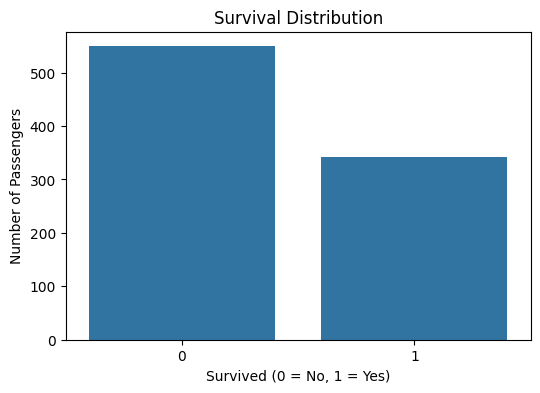

In [7]:
plt.figure(figsize=(6, 4))

sns.countplot(x="Survived", data=df)

plt.title("Survival Distribution")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.show()

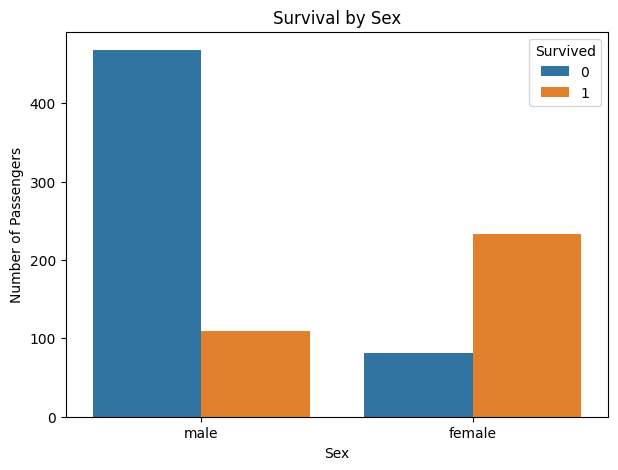

In [8]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Sex", hue="Survived")

plt.title("Survival by Sex")
plt.xlabel("Sex")
plt.ylabel("Number of Passengers")

plt.show()

In [9]:
sex_survival = df.groupby("Sex")["Survived"].mean() * 100

print("Survival Rate by Sex:")
print(sex_survival)

Survival Rate by Sex:
Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64


In [10]:
class_survival = df.groupby("Pclass")["Survived"].mean() * 100

print("Survival Rate by Passenger Class:")
print(class_survival)

Survival Rate by Passenger Class:
Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64


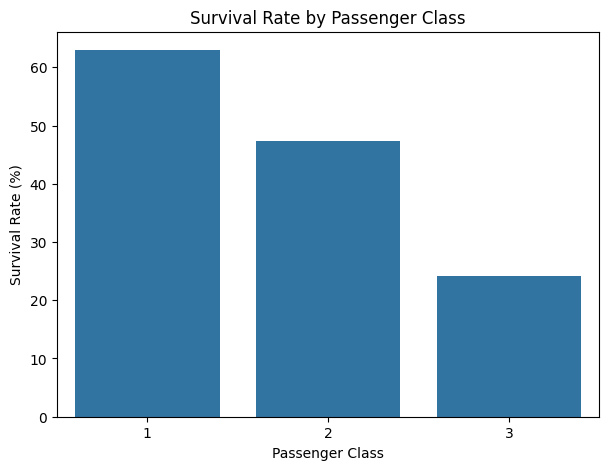

In [11]:
plt.figure(figsize=(7, 5))

sns.barplot(x=class_survival.index, y=class_survival.values)

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate (%)")

plt.show()

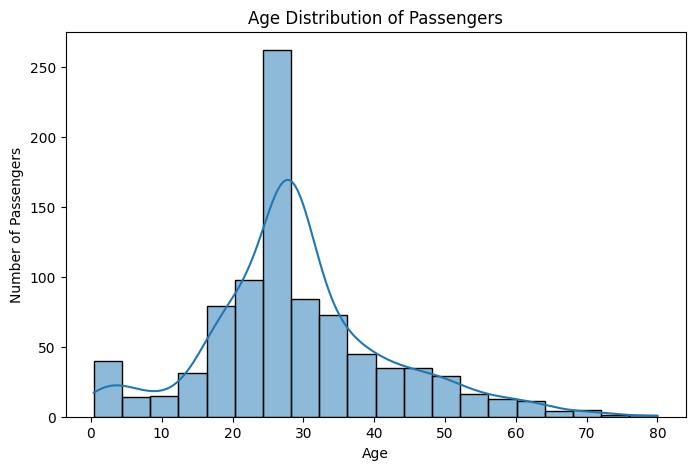

In [12]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Age", bins=20, kde=True) #kde shows overall shafe with smooth curve

plt.title("Age Distribution of Passengers")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

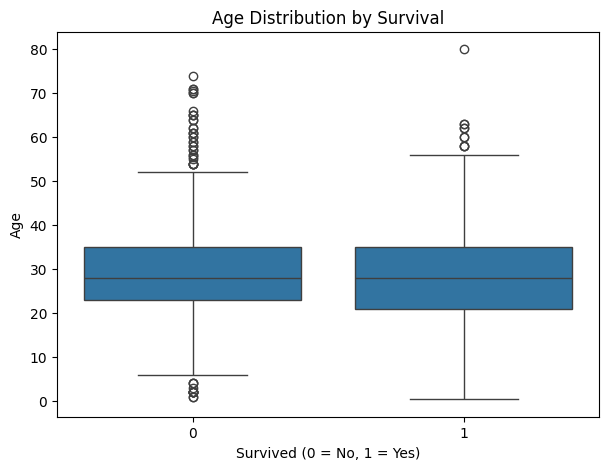

In [13]:
plt.figure(figsize=(7, 5))

sns.boxplot(data=df, x="Survived", y="Age")

plt.title("Age Distribution by Survival")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Age")

plt.show()

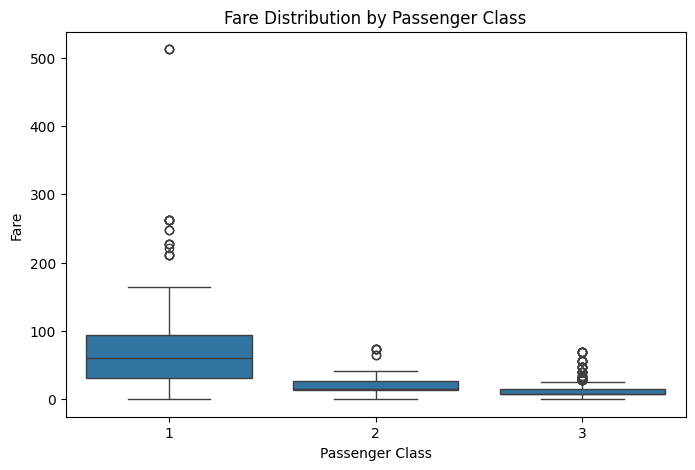

In [14]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Pclass", y="Fare")

plt.title("Fare Distribution by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Fare")

plt.show()

In [15]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

print(df[["SibSp", "Parch", "FamilySize"]].head())

   SibSp  Parch  FamilySize
0      1      0           2
1      1      0           2
2      0      0           1
3      1      0           2
4      0      0           1


In [16]:
family_survival = df.groupby("FamilySize")["Survived"].mean() * 100

print("Survival Rate by Family Size:")
print(family_survival)

Survival Rate by Family Size:
FamilySize
1     30.353818
2     55.279503
3     57.843137
4     72.413793
5     20.000000
6     13.636364
7     33.333333
8      0.000000
11     0.000000
Name: Survived, dtype: float64


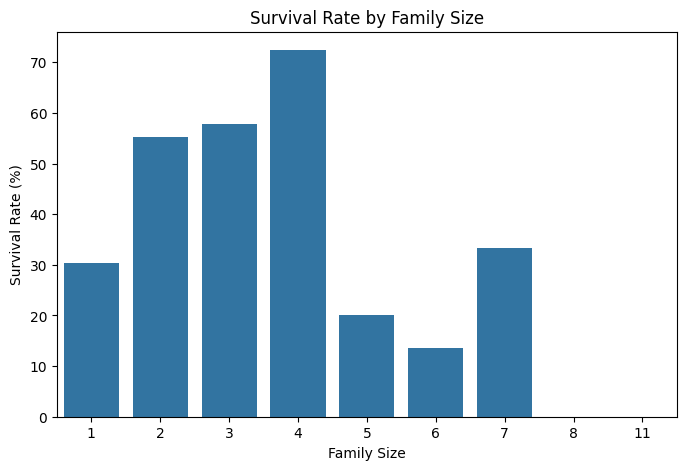

In [17]:
plt.figure(figsize=(8, 5))

sns.barplot(x=family_survival.index, y=family_survival.values)

plt.title("Survival Rate by Family Size")
plt.xlabel("Family Size")
plt.ylabel("Survival Rate (%)")

plt.show()

In [20]:
embarked_survival = df.groupby("Embarked")["Survived"].mean() * 100

print("Survival Rate by Embarkation Port:")
print(embarked_survival)

Survival Rate by Embarkation Port:
Embarked
C    55.357143
Q    38.961039
S    33.900929
Name: Survived, dtype: float64


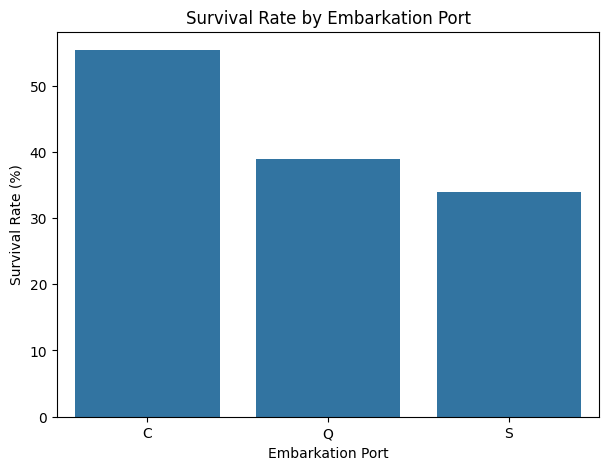

In [21]:
plt.figure(figsize=(7, 5))

sns.barplot(x=embarked_survival.index, y=embarked_survival.values)

plt.title("Survival Rate by Embarkation Port")
plt.xlabel("Embarkation Port")
plt.ylabel("Survival Rate (%)")

plt.show()

In [22]:
correlation = df.select_dtypes(include="number").corr()

print(correlation["Survived"].sort_values(ascending=False))

Survived       1.000000
Fare           0.257307
Parch          0.081629
FamilySize     0.016639
PassengerId   -0.005007
SibSp         -0.035322
Age           -0.064910
Pclass        -0.338481
Name: Survived, dtype: float64


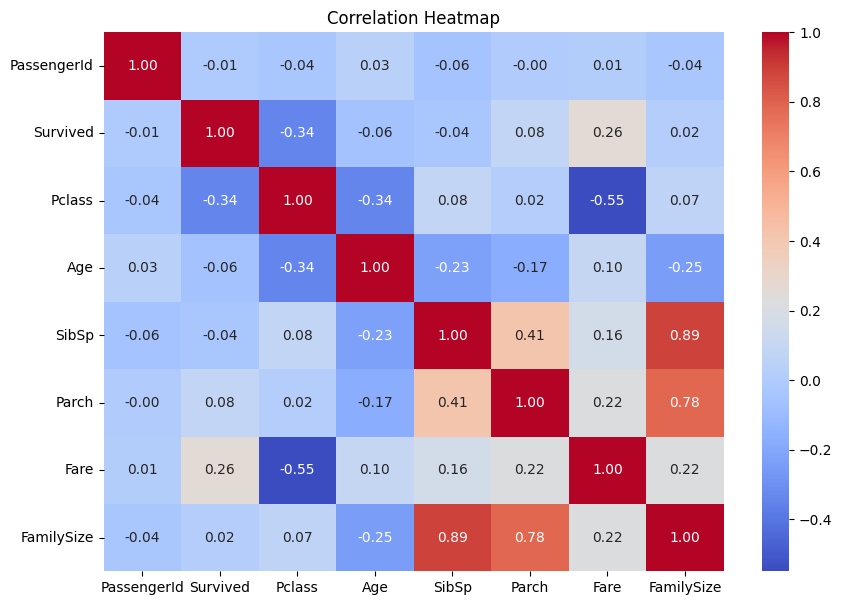

In [23]:
plt.figure(figsize=(10, 7))

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap")
plt.show()

In [24]:
print("Overall Survival Rate:")
print(f"{df['Survived'].mean() * 100:.2f}%")

print("\nSurvival Rate by Sex:")
print(sex_survival.round(2))

print("\nSurvival Rate by Passenger Class:")
print(class_survival.round(2))

print("\nSurvival Rate by Embarkation Port:")
print(embarked_survival.round(2))

Overall Survival Rate:
38.38%

Survival Rate by Sex:
Sex
female    74.20
male      18.89
Name: Survived, dtype: float64

Survival Rate by Passenger Class:
Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64

Survival Rate by Embarkation Port:
Embarked
C    55.36
Q    38.96
S    33.90
Name: Survived, dtype: float64


## Key EDA Insights

1. **Gender strongly influences survival:** Female passengers had a substantially higher survival rate than male passengers. Therefore, Sex may be an important feature for predicting survival.

2. **Passenger class is strongly associated with survival:** First-class passengers had the highest survival rate, followed by second-class and third-class passengers. Pclass therefore appears to be an important predictive feature.

3. **Fare has a positive relationship with survival:** Passengers who paid higher fares generally showed higher survival rates. Fare may provide useful information for a predictive model, although it is also related to passenger class.

4. **Age has a weak linear relationship with survival:** The correlation between Age and Survived was approximately -0.065, indicating that age alone has a relatively weak linear relationship with survival.

5. **Family size does not have a strong overall linear relationship with survival:** The correlation between FamilySize and Survived was approximately 0.017. However, survival rates can vary across different family-size groups, suggesting that the relationship may not be purely linear.

6. **Embarkation port shows different survival rates:** Survival rates varied across the three embarkation ports. This variable may contain useful information for a model, although the difference may also be influenced by other variables such as passenger class.

7. **Numerical correlation highlights Pclass and Fare:** Among the numerical variables, Pclass had a correlation of approximately -0.338 with Survived, while Fare had a correlation of approximately 0.257. These were stronger relationships with survival than most other numerical variables.